# 02 Order trends

Monthly orders and revenue. Trend window: 2017-01 to 2018-08 (assumption A1, see docs/database_schema.md). Months outside it are shown separately.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from src.db import read_table, TREND_START, TREND_END

orders = read_table('fact_orders')
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['month'] = orders['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()
orders['revenue'] = orders['revenue'].astype(float)
print(len(orders), 'orders loaded')

99441 orders loaded


In [2]:
monthly = (orders.groupby('month')
          .agg(all_orders=('order_id', 'size'),
               eligible_orders=('is_revenue_eligible', 'sum'),
               revenue=('revenue', 'sum'))
          .reset_index())
monthly['in_window'] = monthly['month'].between(TREND_START, TREND_END)
monthly

,month,all_orders,eligible_orders,revenue,in_window
0,2016-09-01,4,2,207.86,False
1,2016-10-01,324,290,44507.30,False
2,2016-12-01,1,1,10.90,False
3,2017-01-01,800,787,120098.27,True
4,2017-02-01,1780,1718,244959.35,True
5,2017-03-01,2682,2617,368341.32,True
6,2017-04-01,2404,2377,353842.98,True
7,2017-05-01,3700,3640,503159.19,True
8,2017-06-01,3245,3205,429916.61,True
9,2017-07-01,4026,3946,492287.30,True


In [3]:
win = monthly[monthly['in_window']]
print('months in window:', len(win))
print('orders in window:', int(win['all_orders'].sum()), 'of', int(monthly['all_orders'].sum()))
print('revenue in window:', round(win['revenue'].sum(), 2), 'of', round(monthly['revenue'].sum(), 2))

months in window: 20
orders in window: 99092 of 99441
revenue in window: 13449529.68 of 13494400.74


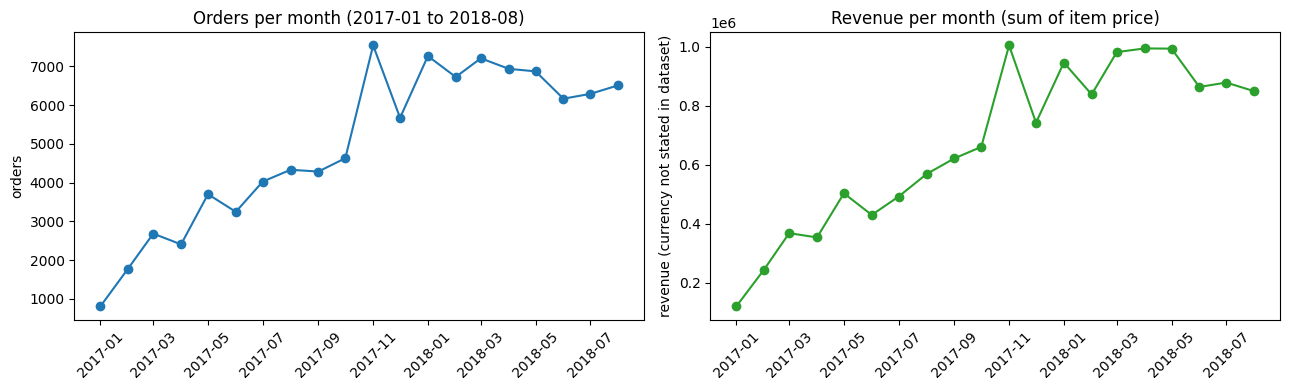

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(win['month'], win['all_orders'], marker='o')
ax[0].set_title('Orders per month (2017-01 to 2018-08)')
ax[0].set_ylabel('orders')
ax[1].plot(win['month'], win['revenue'], marker='o', color='tab:green')
ax[1].set_title('Revenue per month (sum of item price)')
ax[1].set_ylabel('revenue (currency not stated in dataset)')
for a in ax:
    a.tick_params(axis='x', rotation=45)
plt.tight_layout()
out = Path.cwd().parent / 'reports' / 'figures' / 'monthly_orders_revenue.png'
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=150)
plt.show()

## Reading the chart

Write your own observations here after viewing the chart. Describe what you see (levels, the November 2017 peak if present, early-2017 ramp-up) and avoid causal claims the data cannot support.